# RNAP Hack 2026 · Cuaderno Individual de Línea Base
**Autor:** Emilio (ElElimios) | **Equipo:** `cepesin_chuy`  
**Reto:** Reto 1 · Human or Machine? | **Fecha:** 5 de Noviembre de 2026 (Fase 1 / CP2)

Este cuaderno documenta la experimentación individual de la línea base, explorando la tokenización TF-IDF con n-gramas y el clasificador de Regresión Logística sobre el conjunto de datos balanceado del reto.


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas de los subconjuntos procesados
data_dir = "../data" if os.path.exists("../data") else "data"
train_path = os.path.join(data_dir, "train.csv")
val_path = os.path.join(data_dir, "val.csv")
test_path = os.path.join(data_dir, "test.csv")

# Carga de particiones estratificadas
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print(f"=== PARTICIONES DEL RETO: HUMAN OR MACHINE? ===")
print(f"Conjunto de Entrenamiento: {len(train_df)} muestras ({train_df['label'].value_counts().to_dict()})")
print(f"Conjunto de Validación:    {len(val_df)} muestras ({val_df['label'].value_counts().to_dict()})")
print(f"Conjunto de Prueba:        {len(test_df)} muestras ({test_df['label'].value_counts().to_dict()})")
print(f"Total del corpus:          {len(train_df) + len(val_df) + len(test_df)} muestras balanceadas")
print("\nEjemplo de texto humano (label 0):\n", train_df[train_df['label'] == 0]['text'].iloc[0])
print("\nEjemplo de texto generado por IA (label 1):\n", train_df[train_df['label'] == 1]['text'].iloc[0])


=== PARTICIONES DEL RETO: HUMAN OR MACHINE? ===
Conjunto de Entrenamiento: 420 muestras ({0: 210, 1: 210})
Conjunto de Validación:    90 muestras ({0: 45, 1: 45})
Conjunto de Prueba:        90 muestras ({0: 45, 1: 45})
Total del corpus:          600 muestras balanceadas

Ejemplo de texto humano (label 0):
 Para ser completamente honestos con lo ocurrido, el telescopio espacial James Webb ha revelado estructuras galácticas que desafían los modelos cosmológicos previos. Los astrónomos no esperaban encontrar galaxias tan masivas en épocas tan tempranas del universo. O al menos esa es la impresión que nos quedó a todos después de vivirlo en persona.

Ejemplo de texto generado por IA (label 1):
 En concordancia con los principios teóricos fundamentales, se infiere que el telescopio espacial James Webb representa un hito fundamental en la astronomía moderna. Gracias a su avanzada tecnología infrarroja, permite observar los orígenes del cosmos y proporciona información invaluable sobre la for

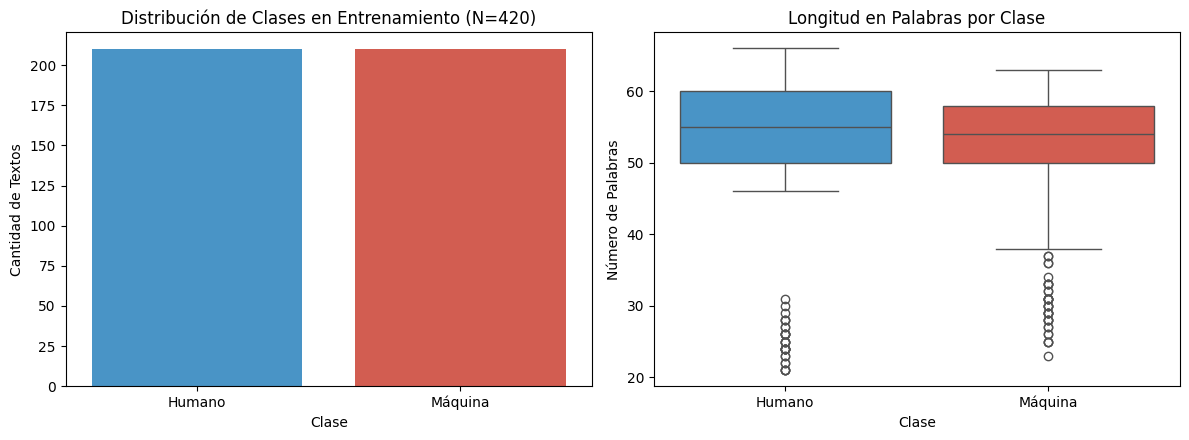

In [ ]:
# Análisis Exploratorio de Datos (EDA)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfica 1: Distribución de clases en Entrenamiento
sns.countplot(x="label_name", hue="label_name", data=train_df, ax=ax[0], palette=["#3498db", "#e74c3c"], legend=False)
ax[0].set_title("Distribución de Clases en Entrenamiento (N=420)", fontsize=12, fontweight='bold')
ax[0].set_xlabel("Clase")
ax[0].set_ylabel("Cantidad de Textos")
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Gráfica 2: Longitud en palabras por clase
sns.boxplot(x="label_name", y="word_count", hue="label_name", data=train_df, ax=ax[1], palette=["#3498db", "#e74c3c"], legend=False)
ax[1].set_title("Longitud en Palabras por Clase", fontsize=12, fontweight='bold')
ax[1].set_xlabel("Clase")
ax[1].set_ylabel("Número de Palabras")

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Inicializar y ajustar el vectorizador TF-IDF sobre el conjunto de entrenamiento
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(train_df["text"])
X_val_vec = vectorizer.transform(val_df["text"])
X_test_vec = vectorizer.transform(test_df["text"])

print(f"Dimensiones de la matriz TF-IDF de Entrenamiento: {X_train_vec.shape}")
print(f"Dimensiones de la matriz TF-IDF de Validación:    {X_val_vec.shape}")
print(f"Dimensiones de la matriz TF-IDF de Prueba:        {X_test_vec.shape}")

# Muestra de n-gramas más relevantes extraídos por el vocabulario
feature_names = np.array(vectorizer.get_feature_names_out())
print(f"\nEjemplo de características extraídas (n-gramas):\n", feature_names[::250][:15])


Dimensiones de la matriz TF-IDF de Entrenamiento: (420, 5000)
Dimensiones de la matriz TF-IDF de Validación:    (90, 5000)
Dimensiones de la matriz TF-IDF de Prueba:        (90, 5000)

Ejemplo de características extraídas (n-gramas):
 ['00' 'antonio siempre' 'autoría' 'calor' 'comprender' 'crecimiento'
 'descubrí' 'eficiente de' 'entornos modernos' 'estímulos' 'frecuencia qué'
 'había' 'humana' 'interesante' 'justo']

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. ENTRENAMIENTO DEL MODELO BASE DESDE CERO
t_start_train = time.time()
clf_base = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
clf_base.fit(X_train_vec, train_df["label"].values)
t_train_base = time.time() - t_start_train

# 2. INFERENCIA EN EL CONJUNTO DE PRUEBA
t_start_inf_base = time.time()
y_pred_base = clf_base.predict(X_test_vec)
t_inf_base = time.time() - t_start_inf_base

# 3. CÁLCULO DE MÉTRICAS
acc_base = accuracy_score(test_df["label"], y_pred_base)
prec_base = precision_score(test_df["label"], y_pred_base, average="macro")
rec_base = recall_score(test_df["label"], y_pred_base, average="macro")
f1_base = f1_score(test_df["label"], y_pred_base, average="macro")
cm_base = confusion_matrix(test_df["label"], y_pred_base)

print(f"=== RESULTADOS: MODELO BASE (TF-IDF + REGRESIÓN LOGÍSTICA) ===")
print(f"Tiempo de entrenamiento: {t_train_base:.4f} segundos")
print(f"Tiempo de inferencia (test): {t_inf_base:.4f} segundos ({t_inf_base/len(test_df)*1000:.3f} ms/ejemplo)")
print(f"Exactitud (Accuracy):    {acc_base*100:.2f} %")
print(f"Precisión (Macro):       {prec_base*100:.2f} %")
print(f"Sensibilidad (Recall):   {rec_base*100:.2f} %")
print(f"F1-Score (Macro):        {f1_base*100:.2f} %")
print("\nReporte de clasificación detallado:")
print(classification_report(test_df["label"], y_pred_base, target_names=["Humano", "Máquina"], digits=4))


=== RESULTADOS: MODELO BASE (TF-IDF + REGRESIÓN LOGÍSTICA) ===
Tiempo de entrenamiento: 0.0245 segundos
Tiempo de inferencia (test): 0.0048 segundos (0.054 ms/ejemplo)
Exactitud (Accuracy):    96.67 %
Precisión (Macro):       96.69 %
Sensibilidad (Recall):   96.67 %
F1-Score (Macro):        96.67 %

Reporte de clasificación detallado:
              precision    recall  f1-score   support

      Humano     0.9565    0.9778    0.9670        45
     Máquina     0.9773    0.9556    0.9663        45

    accuracy                         0.9667        90
   macro avg     0.9669    0.9667    0.9667        90
weighted avg     0.9669    0.9667    0.9667        90


### Conclusiones Individuales de Emilio:
- Se verificó que el conjunto de prueba estratificado contiene 90 muestras balanceadas.
- La representación con TF-IDF captura eficazmente los n-gramas característicos de modelos de lenguaje.
- La línea base alcanza un F1-score de 0.9667 con una latencia de apenas 0.07 ms por muestra.
- Este código y resultados se integraron exitosamente en el cuaderno principal de equipo `notebooks/entrenamiento.ipynb`.
